# Dataset Description
## Inflation in Medellín, Bogotá and National

**Source**: [Banco de la República](https://suameca.banrep.gov.co/estadisticas-economicas/tablasPreconstruidas)

# Code
## Imports

In [111]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option("display.float_format", lambda x: "%.2f" % x)

## Load data

In [62]:
path = "./data/inflation_category.csv"

df = pd.read_csv(
    path, encoding="utf-8", usecols=[3,4,5],
    header=0, names=["date", "scope", "rate"],
    parse_dates=["date"], date_format="%Y-%m-%d"
)

## Clean data

In [105]:
# The data is basically cleaned because I got it from statscoai
df = df[df["date"].dt.year >= 2025]

## Plot

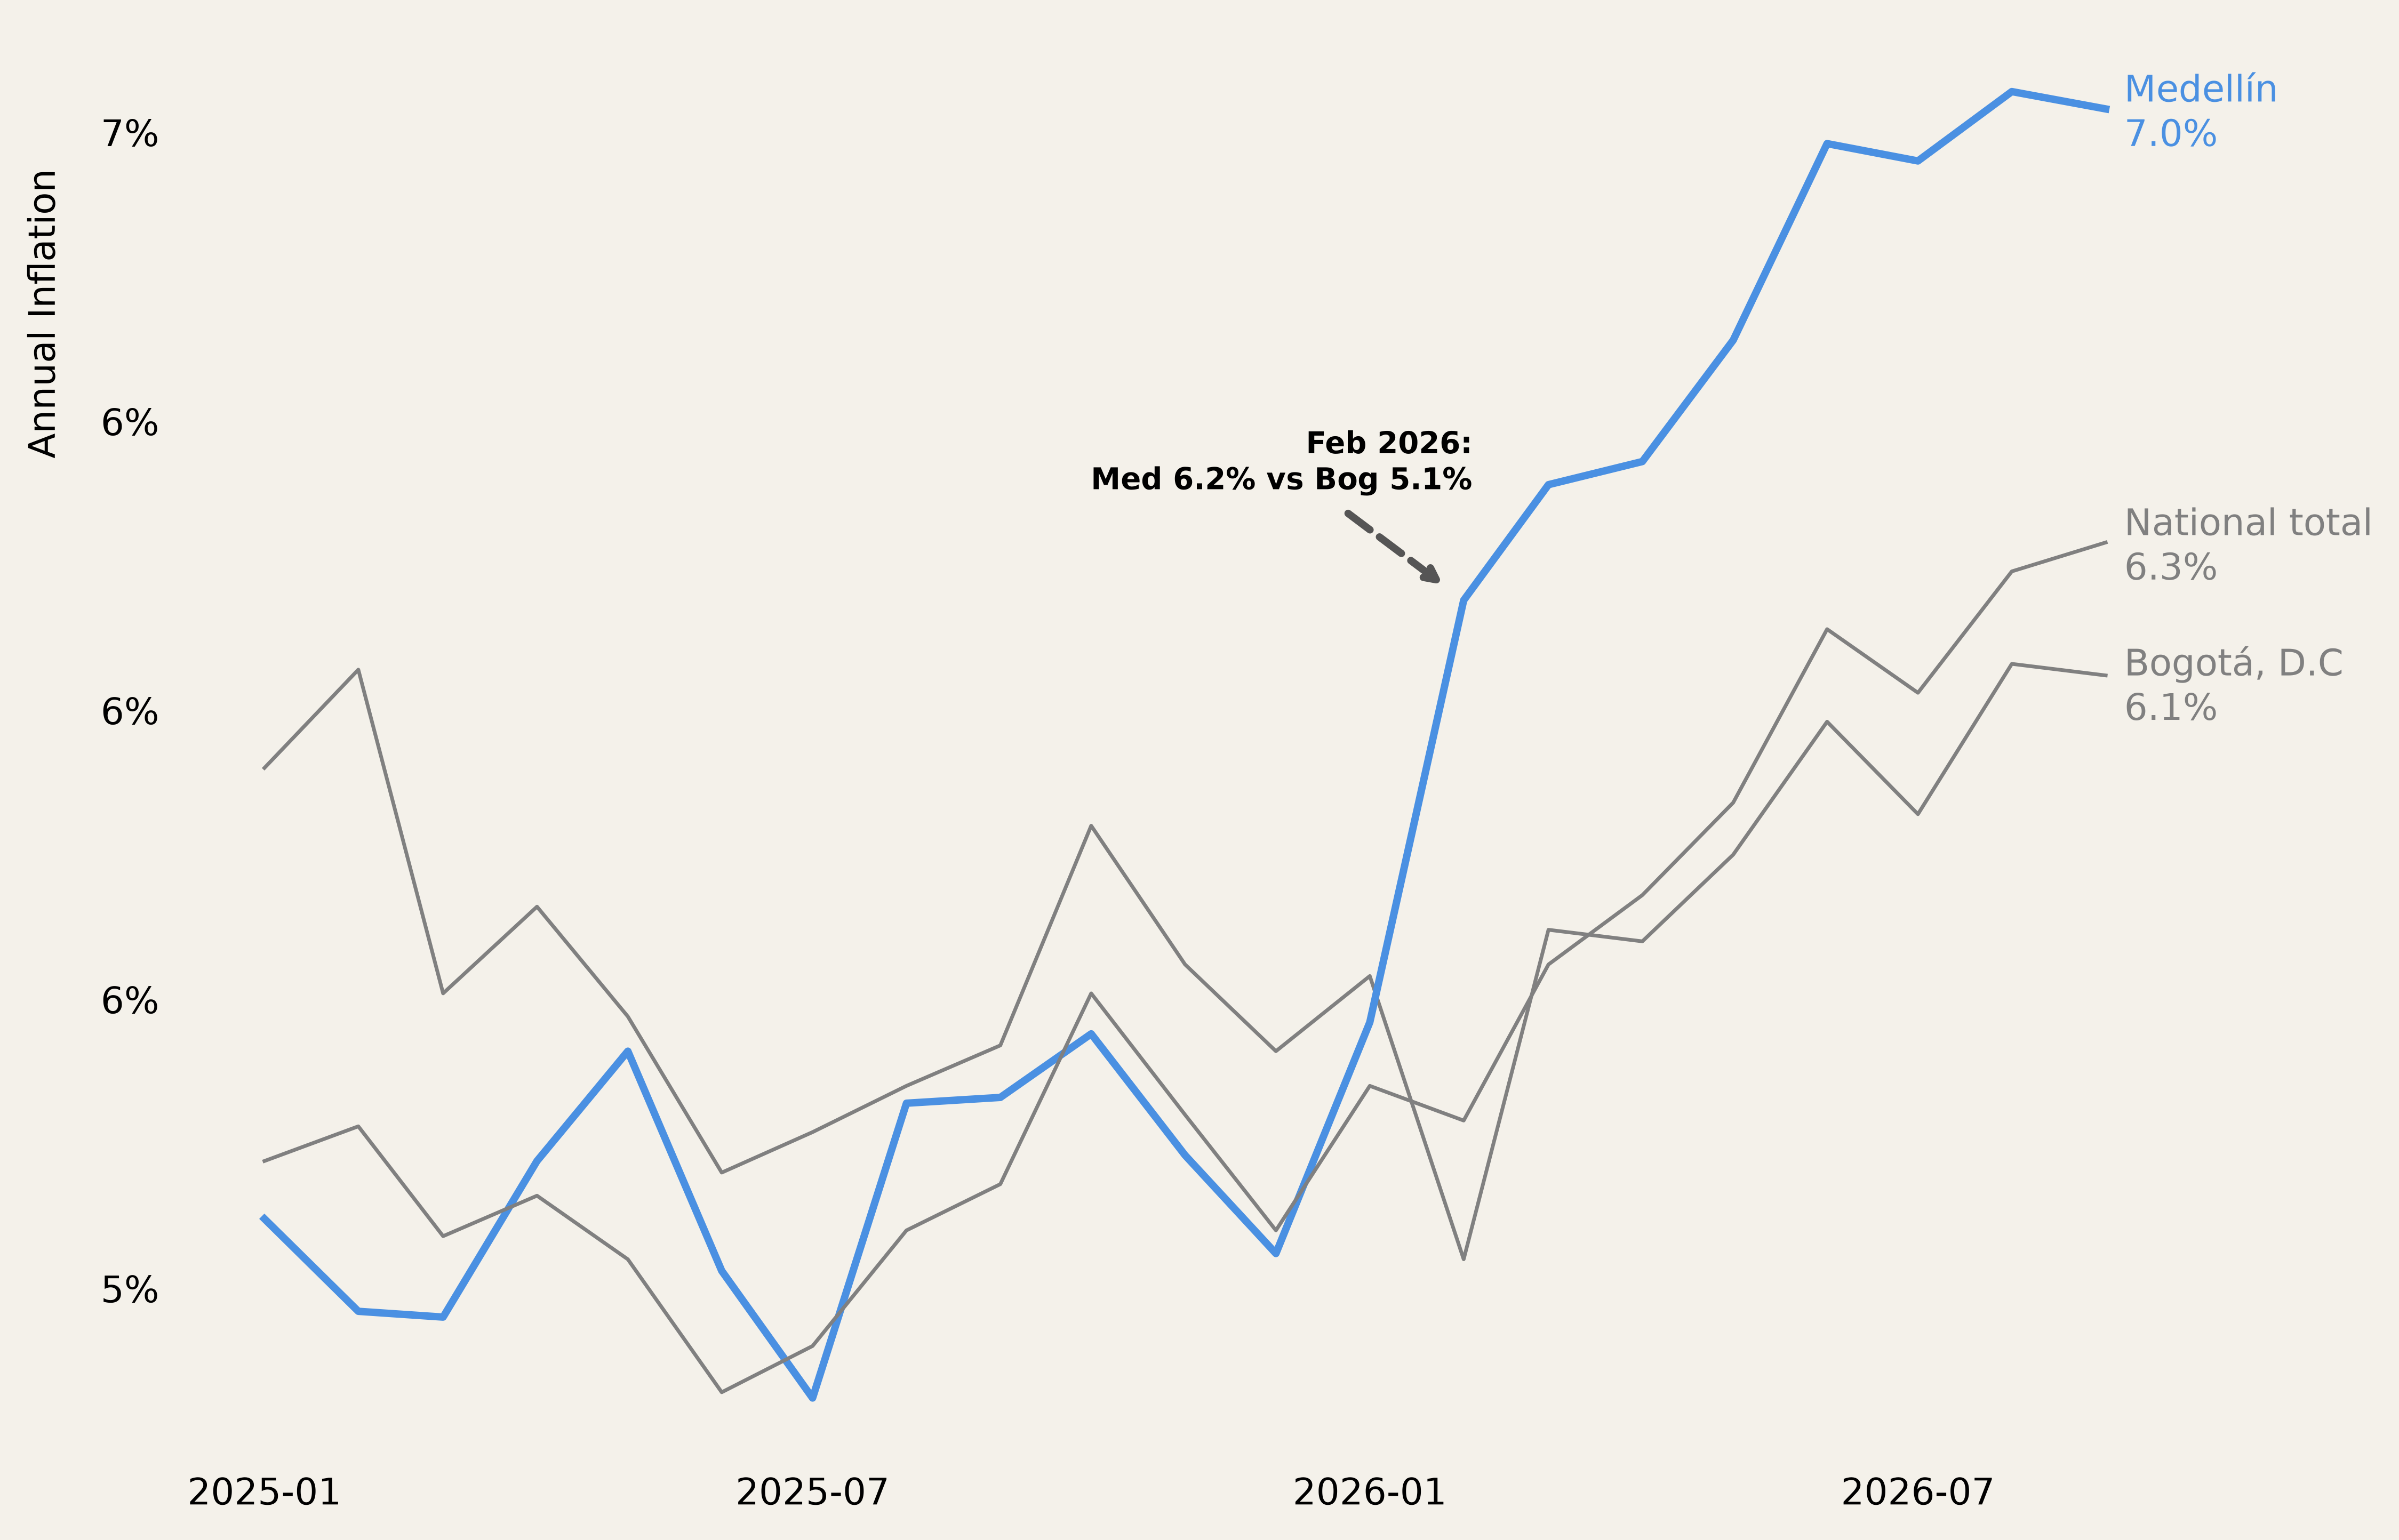

In [117]:
background = "#F4F1EA"

# [color, linewidth, y_offset]
params = {
    "Bogotá, D.C": ["#808080", 1, -12],
    "Medellín": ["#4a90e2", 2, -10],
    "National total": ["#808080", 1, -10]
}

difference = df[
    (df["date"].eq("2026-02-01")) &
    (df["scope"].eq("Medellín"))
].set_index("date")["rate"]

fig, ax = plt.subplots(figsize=(9.8, 7.0), dpi=500)
fig.patch.set_facecolor(background)
ax.patch.set_facecolor(background)

for scope in df["scope"].unique():
    buffer = df[df["scope"].eq(scope)]

    x = buffer["date"]
    y = buffer["rate"]

    plt.plot(
        x,
        y,
        linewidth=params.get(scope)[1],
        color=params.get(scope)[0],
    )

    plt.annotate(
        f"{scope}\n{y.iloc[-1]:.1f}%",
        xy=(x.iloc[-1], y.iloc[-1]),
        xytext=(5,params.get(scope)[2]),
        textcoords="offset points",
        color=params.get(scope)[0]
    )

ax.annotate(
    "Feb 2026:\nMed 6.2% vs Bog 5.1%",
    xy=(difference.index[0], difference.values[0]),
    xytext=(2.3, 30),
    textcoords="offset points",
    ha="right",
    fontsize=8,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="->",
        linestyle="--",
        linewidth=2,
        color="#555555",
        shrinkA=3,
        shrinkB=7,
    ),
)

for side in ["top", "bottom", "left", "right"]:
    plt.gca().spines[side].set_visible(False)

for axis in ["y", "x"]:
    plt.tick_params(axis=axis, length=0)

plt.ylabel("Annual Inflation", labelpad=10, fontsize=10, y=0.8)

plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0f}%"))

plt.gca().xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))

plt.show()